# WellPerf — VFM + PTA results
SOCAR Hackathon 2026, team Enthuzone. Cells were executed against the WellPerf engine (`wellperf-Platform/engine`) with Jan–Sep 2025 loaded.

In [1]:
import json, pickle, urllib.request
import pandas as pd
import matplotlib.pyplot as plt
ENGINE = "http://127.0.0.1:8000"
get = lambda p: json.load(urllib.request.urlopen(ENGINE + p))
print("engine stages:", get("/api/status")["stages"])

engine stages: {'clean': 'done', 'vfm': 'done', 'pta': 'done'}


## 1. Trained VFM model (.pkl)

In [2]:
model = pickle.load(open("../model/vfm_model.pkl", "rb"))
print(type(model).__name__)
m = get("/api/model")
print(json.dumps({k: m[k] for k in m if "mape" in k.lower()}, indent=1)[:1200])

VFMModel
{}


## 2. Phase 1 — VFM daily predictions

In [3]:
vfm = pd.read_csv("../vfm_daily_predictions.csv")
print(vfm.shape)
print(vfm.head(10).to_string())
print(vfm.describe().round(1).to_string())

(2730, 5)
    timestamp well_name  oil_rate_stbd  water_rate_stbd  gas_rate_mscfd
0  2025-01-01     GL-01         1225.7            826.3           334.7
1  2025-01-02     GL-01         1224.0            826.1           334.2
2  2025-01-03     GL-01         1226.7            828.9           335.0
3  2025-01-04     GL-01         1223.4            827.6           334.1
4  2025-01-05     GL-01         1219.0            825.6           332.9
5  2025-01-06     GL-01         1214.0            823.2           331.5
6  2025-01-07     GL-01         1212.6            823.2           331.1
7  2025-01-08     GL-01         1208.3            821.2           329.9
8  2025-01-09     GL-01         1203.8            819.1           328.7
9  2025-01-10     GL-01         1201.9            818.7           328.2
       oil_rate_stbd  water_rate_stbd  gas_rate_mscfd
count         2730.0           2730.0          2730.0
mean          1424.6            716.7           365.5
std           1064.8            520.

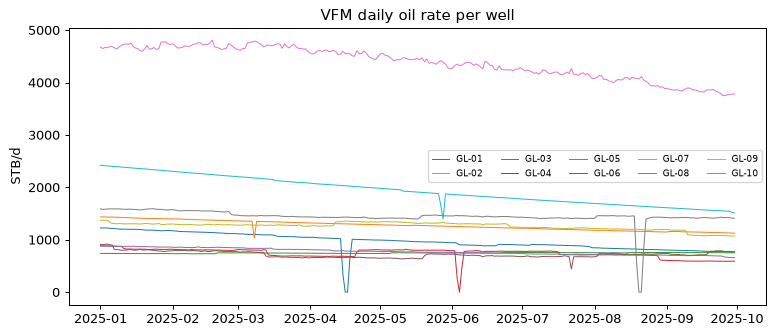

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
for w, g in vfm.groupby(vfm.columns[1]):
    ax.plot(pd.to_datetime(g.iloc[:, 0]), g.iloc[:, 2], lw=0.8, label=w)
ax.set_title("VFM daily oil rate per well"); ax.set_ylabel("STB/d"); ax.legend(ncol=5, fontsize=7)
plt.show()

## 3. Phase 2 — PTA results (Horner, k, skin, ΔP-skin)

In [5]:
pta = pd.DataFrame(get("/api/results/pta")["results"])
cols = ["well_name","shut_in_start","horner_slope_psi_per_cycle","permeability_md","skin","delta_p_skin_psi","iarf_quality"]
print(pta[cols].round(2).to_string(index=False))

well_name       shut_in_start  horner_slope_psi_per_cycle  permeability_md  skin  delta_p_skin_psi   iarf_quality
    GL-01 2025-04-15T08:00:00                       23.25           109.15  5.73            115.69 no_radial_flow
    GL-02 2025-03-08T14:23:00                       54.04            58.17 -0.70            -32.97           good
    GL-04 2025-06-03T08:00:00                      148.42            53.11 -1.38           -178.04           good
    GL-06 2025-07-22T03:11:00                       15.43           291.74  1.74             23.29           good
    GL-08 2025-08-19T09:00:00                       94.62            41.95 -1.72           -141.65           good
    GL-10 2025-05-27T21:04:00                       28.86           188.23  2.00             50.05 no_radial_flow


## 4. PTA plots per shut-in (also saved to `../pta_plots/`)

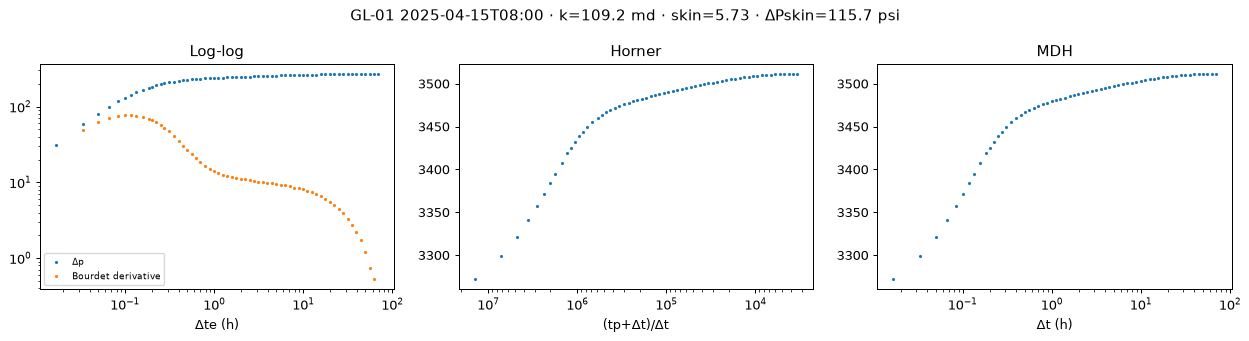

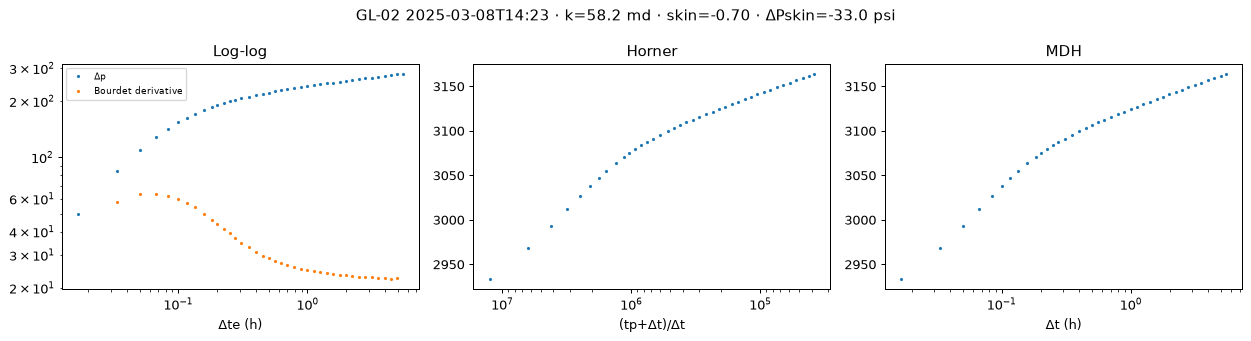

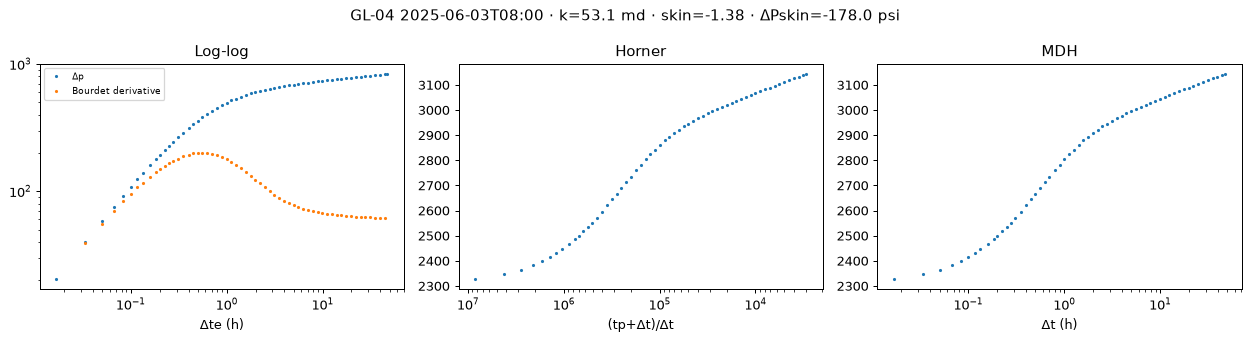

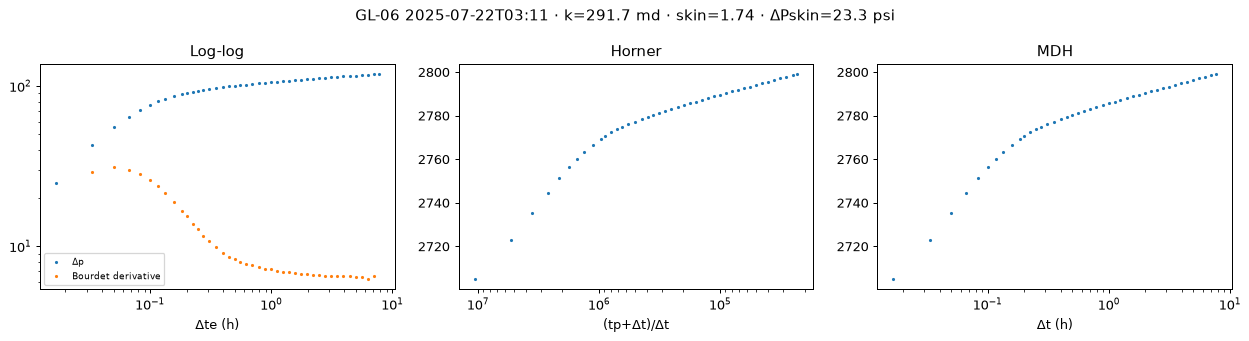

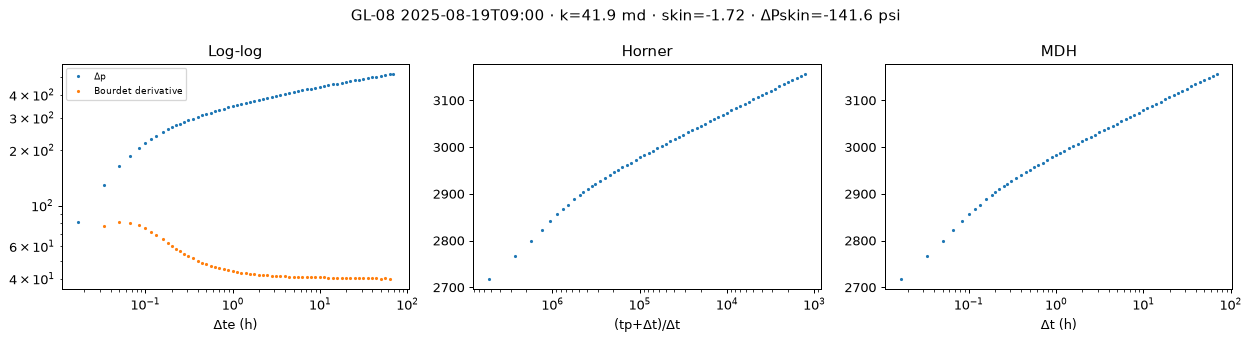

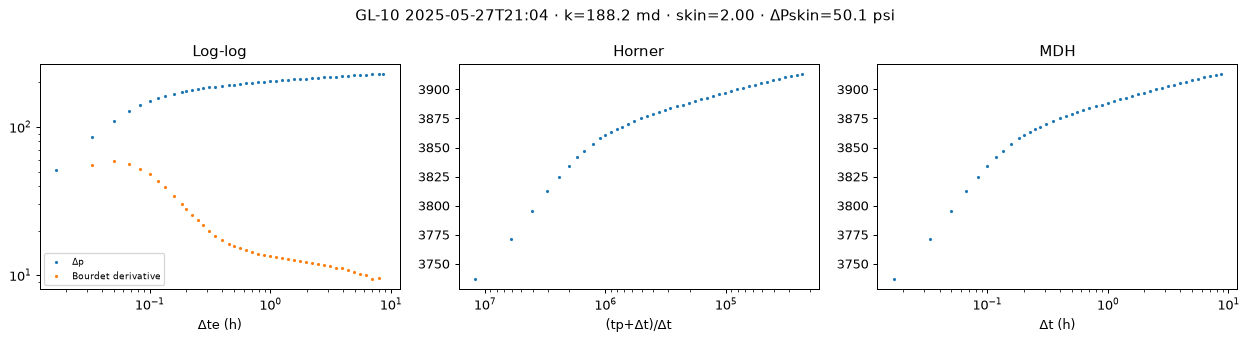

In [6]:
for eid in pta.event_id:
    d = get(f"/api/pta/{eid}")
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
    L = d["loglog"]; ax[0].loglog(L["dte"], L["dp"], ".", ms=3, label="Δp"); ax[0].loglog(L["dte"], L["deriv"], ".", ms=3, label="Bourdet derivative")
    ax[0].set_title("Log-log"); ax[0].set_xlabel("Δte (h)"); ax[0].legend(fontsize=7)
    H = d["horner"]; ax[1].plot(H["ht"], H["pws"], ".", ms=3); ax[1].invert_xaxis(); ax[1].set_xscale("log"); ax[1].set_title("Horner"); ax[1].set_xlabel("(tp+Δt)/Δt")
    M = d["mdh"]; ax[2].semilogx(M["dt"], M["pws"], ".", ms=3); ax[2].set_title("MDH"); ax[2].set_xlabel("Δt (h)")
    r = d["result"]
    fig.suptitle(f"{d['well_name']} {d['shut_in_start'][:16]} · k={r['permeability_md']:.1f} md · skin={r['skin']:.2f} · ΔPskin={r['delta_p_skin_psi']:.1f} psi")
    fig.tight_layout(); fig.savefig(f"../pta_plots/{eid}.png", dpi=130)
    plt.show()